<a href="https://colab.research.google.com/github/Supan-Roy/financial-scam-analysis/blob/main/notebooks/12_integrated_multilevel_inference.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

# ============================================================
# NOTEBOOK 12: INTEGRATED MULTI-LEVEL INFERENCE
# Cell 1: Environment Setup and Artifact Configuration
# ============================================================

import os
import json
import random
import time
import gc
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from google.colab import drive

# ------------------------------------------------------------
# 1. Mount Google Drive
# ------------------------------------------------------------
drive.mount("/content/drive")

# ------------------------------------------------------------
# 2. Project Directories
# ------------------------------------------------------------
ROOT_DIR = Path("/content/drive/MyDrive/financial-scam-analysis")

DATA_DIR = ROOT_DIR / "data"
MODEL_DIR = ROOT_DIR / "models"
OUTPUT_DIR = ROOT_DIR / "outputs"

BINARY_MODEL_DIR = MODEL_DIR / "distilbert_binary"

MULTILEVEL_MODEL_DIR = (
    MODEL_DIR / "distilbert_multilevel" / "checkpoints"
)

INFERENCE_OUTPUT_DIR = (
    OUTPUT_DIR / "integrated_inference"
)

INFERENCE_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 3. Model Checkpoint Paths
# ------------------------------------------------------------
MODEL_PATHS = {
    "binary": BINARY_MODEL_DIR,

    "subtype": (
        MULTILEVEL_MODEL_DIR
        / "subtype_full_combined"
        / "best_model"
    ),

    "intent": (
        MULTILEVEL_MODEL_DIR
        / "intent_full_combined"
        / "best_model"
    ),

    "tactics": (
        MULTILEVEL_MODEL_DIR
        / "tactics_full_combined"
        / "best_model"
    )
}

# ------------------------------------------------------------
# 4. Reproducibility
# ------------------------------------------------------------
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ------------------------------------------------------------
# 5. Device Configuration
# ------------------------------------------------------------
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# ------------------------------------------------------------
# 6. Inference Configuration
# ------------------------------------------------------------
BASE_MODEL_NAME = "distilbert/distilbert-base-uncased"

MAX_LENGTH = 512
BINARY_THRESHOLD = 0.5
TACTIC_THRESHOLD = 0.5

# ------------------------------------------------------------
# 7. Verify Model Artifacts
# ------------------------------------------------------------
print("=" * 75)
print("INTEGRATED MULTI-LEVEL INFERENCE — ENVIRONMENT")
print("=" * 75)

print(f"\nProject directory: {ROOT_DIR}")
print(f"Device: {DEVICE}")

if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(
        f"GPU memory: "
        f"{torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB"
    )
else:
    print("GPU unavailable — inference will use CPU.")

print("\nMODEL ARTIFACT VERIFICATION")
print("-" * 75)

for model_name, model_path in MODEL_PATHS.items():

    config_path = model_path / "config.json"
    weights_path = model_path / "model.safetensors"

    # Some saved models may use pytorch_model.bin.
    alternative_weights_path = model_path / "pytorch_model.bin"

    exists = (
        model_path.exists()
        and config_path.exists()
        and (
            weights_path.exists()
            or alternative_weights_path.exists()
        )
    )

    print(
        f"{model_name.upper():10s} | "
        f"{'AVAILABLE' if exists else 'MISSING'} | "
        f"{model_path}"
    )

    assert exists, (
        f"Required model artifact missing or incomplete: {model_path}"
    )

print("\n" + "=" * 75)
print("ENVIRONMENT INITIALIZATION COMPLETE")
print("=" * 75)


Mounted at /content/drive
INTEGRATED MULTI-LEVEL INFERENCE — ENVIRONMENT

Project directory: /content/drive/MyDrive/financial-scam-analysis
Device: cuda
GPU: Tesla T4
GPU memory: 14.56 GB

MODEL ARTIFACT VERIFICATION
---------------------------------------------------------------------------
BINARY     | AVAILABLE | /content/drive/MyDrive/financial-scam-analysis/models/distilbert_binary
SUBTYPE    | AVAILABLE | /content/drive/MyDrive/financial-scam-analysis/models/distilbert_multilevel/checkpoints/subtype_full_combined/best_model
INTENT     | AVAILABLE | /content/drive/MyDrive/financial-scam-analysis/models/distilbert_multilevel/checkpoints/intent_full_combined/best_model
TACTICS    | AVAILABLE | /content/drive/MyDrive/financial-scam-analysis/models/distilbert_multilevel/checkpoints/tactics_full_combined/best_model

ENVIRONMENT INITIALIZATION COMPLETE


In [2]:
# ============================================================
# Cell 2: Inference Libraries and Model Configuration
# ============================================================

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

import torch.nn.functional as F

from sklearn.preprocessing import LabelEncoder, MultiLabelBinarizer

from collections import OrderedDict

# ------------------------------------------------------------
# 1. Task Configuration
# ------------------------------------------------------------

TASK_CONFIG = {
    "binary": {
        "num_labels": 2,
        "problem_type": "single_label_classification",
        "max_length": MAX_LENGTH
    },
    "subtype": {
        "num_labels": 13,
        "problem_type": "single_label_classification",
        "max_length": MAX_LENGTH
    },
    "intent": {
        "num_labels": 5,
        "problem_type": "single_label_classification",
        "max_length": MAX_LENGTH
    },
    "tactics": {
        "num_labels": 9,
        "problem_type": "multi_label_classification",
        "max_length": MAX_LENGTH
    }
}

# ------------------------------------------------------------
# 2. Binary Classification Labels
# ------------------------------------------------------------

BINARY_LABELS = {
    0: "legitimate",
    1: "financial_scam"
}

# ------------------------------------------------------------
# 3. Subtype Label Mapping
# ------------------------------------------------------------

SUBTYPE_LABELS = [
    "account_verification",
    "card_transaction_alert",
    "charity_donation",
    "family_emergency_request",
    "investment_crypto",
    "invoice_payment_request",
    "job_task_commission",
    "loan_offer",
    "prize_reward",
    "recovery_support",
    "refund_chargeback",
    "romance_financial_manipulation",
    "tax_payment"
]

# ------------------------------------------------------------
# 4. Intent Label Mapping
# ------------------------------------------------------------

INTENT_LABELS = [
    "gain_account_or_device_access",
    "induce_fraudulent_investment",
    "induce_payment_or_transfer",
    "obtain_credentials_or_codes",
    "obtain_personal_or_financial_information"
]

# ------------------------------------------------------------
# 5. Social-Engineering Tactic Label Mapping
# ------------------------------------------------------------

TACTIC_LABELS = [
    "authority_impersonation",
    "emotional_manipulation",
    "false_legitimacy",
    "fear_or_threat",
    "reward_or_benefit",
    "scarcity",
    "secrecy",
    "trust_exploitation",
    "urgency"
]

# ------------------------------------------------------------
# 6. Configuration Validation
# ------------------------------------------------------------

assert len(SUBTYPE_LABELS) == TASK_CONFIG["subtype"]["num_labels"]
assert len(INTENT_LABELS) == TASK_CONFIG["intent"]["num_labels"]
assert len(TACTIC_LABELS) == TASK_CONFIG["tactics"]["num_labels"]

assert len(set(SUBTYPE_LABELS)) == len(SUBTYPE_LABELS)
assert len(set(INTENT_LABELS)) == len(INTENT_LABELS)
assert len(set(TACTIC_LABELS)) == len(TACTIC_LABELS)

print("=" * 75)
print("INFERENCE CONFIGURATION")
print("=" * 75)

for task, config in TASK_CONFIG.items():
    print(
        f"{task.upper():10s} | "
        f"Labels: {config['num_labels']:2d} | "
        f"Type: {config['problem_type']}"
    )

print("\nSubtype labels:", len(SUBTYPE_LABELS))
print("Intent labels:", len(INTENT_LABELS))
print("Tactic labels:", len(TACTIC_LABELS))

print("\nBinary threshold:", BINARY_THRESHOLD)
print("Tactic threshold:", TACTIC_THRESHOLD)
print("Maximum sequence length:", MAX_LENGTH)

print("\nConfiguration validation successful.")

INFERENCE CONFIGURATION
BINARY     | Labels:  2 | Type: single_label_classification
SUBTYPE    | Labels: 13 | Type: single_label_classification
INTENT     | Labels:  5 | Type: single_label_classification
TACTICS    | Labels:  9 | Type: multi_label_classification

Subtype labels: 13
Intent labels: 5
Tactic labels: 9

Binary threshold: 0.5
Tactic threshold: 0.5
Maximum sequence length: 512

Configuration validation successful.


In [3]:
# ============================================================
# Cell 3: Load Tokenizer and All Trained Models
# ============================================================

# ------------------------------------------------------------
# 1. Load Shared Tokenizer
# ------------------------------------------------------------

tokenizer = AutoTokenizer.from_pretrained(
    BASE_MODEL_NAME
)

# ------------------------------------------------------------
# 2. Load Four Trained Models
# ------------------------------------------------------------

models = {}

for task_name, model_path in MODEL_PATHS.items():

    print(f"\nLoading {task_name.upper()} model...")

    model = AutoModelForSequenceClassification.from_pretrained(
        str(model_path)
    )

    model.to(DEVICE)
    model.eval()

    models[task_name] = model

    print(f"  Loaded successfully")
    print(f"  Number of labels: {model.config.num_labels}")
    print(f"  Problem type: {model.config.problem_type}")
    print(f"  Device: {next(model.parameters()).device}")

# ------------------------------------------------------------
# 3. Inspect Saved Label Configurations
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("SAVED MODEL LABEL CONFIGURATIONS")
print("=" * 75)

for task_name, model in models.items():

    print(f"\n{task_name.upper()}")
    print("-" * 50)

    print("id2label:")
    print(model.config.id2label)

    print("\nlabel2id:")
    print(model.config.label2id)

# ------------------------------------------------------------
# 4. Validate Model Dimensions
# ------------------------------------------------------------

for task_name, model in models.items():

    expected_labels = TASK_CONFIG[task_name]["num_labels"]

    assert model.config.num_labels == expected_labels, (
        f"{task_name}: expected {expected_labels} labels, "
        f"found {model.config.num_labels}"
    )

assert tokenizer.model_max_length >= MAX_LENGTH

# ------------------------------------------------------------
# 5. Memory Summary
# ------------------------------------------------------------

total_parameters = sum(
    parameter.numel()
    for model in models.values()
    for parameter in model.parameters()
)

print("\n" + "=" * 75)
print("MODEL LOADING COMPLETE")
print("=" * 75)

print(f"Models loaded: {len(models)}")
print(f"Tokenizer vocabulary size: {tokenizer.vocab_size:,}")
print(f"Total parameters across models: {total_parameters:,}")
print(f"Total parameters (millions): {total_parameters / 1e6:.2f}")

if torch.cuda.is_available():
    print(
        f"GPU memory allocated: "
        f"{torch.cuda.memory_allocated() / 1024**3:.2f} GB"
    )

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]


Loading BINARY model...


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

... (3 outputs left out)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

  Loaded successfully
  Number of labels: 5
  Problem type: single_label_classification
  Device: cuda:0

Loading TACTICS model...


Loading weights:   0%|          | 0/104 [00:01<?, ?it/s]

  Loaded successfully
  Number of labels: 9
  Problem type: multi_label_classification
  Device: cuda:0

SAVED MODEL LABEL CONFIGURATIONS

BINARY
--------------------------------------------------
id2label:
{0: 'LEGITIMATE', 1: 'SCAM'}

label2id:
{'LEGITIMATE': 0, 'SCAM': 1}

SUBTYPE
--------------------------------------------------
id2label:
{0: 'account_verification', 1: 'card_transaction_alert', 2: 'charity_donation', 3: 'family_emergency_request', 4: 'investment_crypto', 5: 'invoice_payment_request', 6: 'job_task_commission', 7: 'loan_offer', 8: 'prize_reward', 9: 'recovery_support', 10: 'refund_chargeback', 11: 'romance_financial_manipulation', 12: 'tax_payment'}

label2id:
{'account_verification': 0, 'card_transaction_alert': 1, 'charity_donation': 2, 'family_emergency_request': 3, 'investment_crypto': 4, 'invoice_payment_request': 5, 'job_task_commission': 6, 'loan_offer': 7, 'prize_reward': 8, 'recovery_support': 9, 'refund_chargeback': 10, 'romance_financial_manipulation': 11

In [4]:
# ============================================================
# Cell 4: Tokenization and Model Input Compatibility Test
# ============================================================

# ------------------------------------------------------------
# 1. Sample Messages
# ------------------------------------------------------------

sample_messages = [
    (
        "Your bank account has been temporarily suspended. "
        "Verify your identity immediately using the secure link."
    ),
    (
        "Thank you for attending today's lecture. "
        "The assignment submission deadline is Friday."
    )
]

# ------------------------------------------------------------
# 2. Tokenization
# ------------------------------------------------------------

encoded_inputs = tokenizer(
    sample_messages,
    padding=True,
    truncation=True,
    max_length=MAX_LENGTH,
    return_tensors="pt"
)

encoded_inputs = {
    key: value.to(DEVICE)
    for key, value in encoded_inputs.items()
}

print("=" * 75)
print("TOKENIZATION VALIDATION")
print("=" * 75)

print("Input batch size:", len(sample_messages))
print("Input tensor shape:", encoded_inputs["input_ids"].shape)
print("Attention mask shape:", encoded_inputs["attention_mask"].shape)

# ------------------------------------------------------------
# 3. Run Compatibility Inference
# ------------------------------------------------------------

print("\nMODEL OUTPUT VALIDATION")
print("-" * 75)

with torch.inference_mode():

    for task_name, model in models.items():

        outputs = model(**encoded_inputs)

        logits = outputs.logits

        assert logits.shape == (
            len(sample_messages),
            TASK_CONFIG[task_name]["num_labels"]
        )

        if task_name == "tactics":
            probabilities = torch.sigmoid(logits)
        else:
            probabilities = torch.softmax(logits, dim=-1)

        print(f"\n{task_name.upper()}")
        print("Logits shape:", tuple(logits.shape))
        print("Probability shape:", tuple(probabilities.shape))

        print(
            "Probability range:",
            f"{probabilities.min().item():.4f}",
            "to",
            f"{probabilities.max().item():.4f}"
        )

        if task_name != "tactics":
            probability_sums = probabilities.sum(dim=-1)

            print(
                "Softmax row sums:",
                probability_sums.cpu().numpy().round(4)
            )

            assert torch.allclose(
                probability_sums,
                torch.ones_like(probability_sums),
                atol=1e-5
            )

        else:
            print(
                "Tactic probabilities use independent sigmoid outputs."
            )

# ------------------------------------------------------------
# 4. Token Length Inspection
# ------------------------------------------------------------

print("\nTOKEN LENGTHS")
print("-" * 75)

for message in sample_messages:

    token_count = len(
        tokenizer(
            message,
            truncation=False
        )["input_ids"]
    )

    print(f"{token_count:4d} tokens | {message[:85]}...")

print("\n" + "=" * 75)
print("TOKENIZATION AND MODEL COMPATIBILITY VERIFIED")
print("=" * 75)

TOKENIZATION VALIDATION
Input batch size: 2
Input tensor shape: torch.Size([2, 19])
Attention mask shape: torch.Size([2, 19])

MODEL OUTPUT VALIDATION
---------------------------------------------------------------------------

BINARY
Logits shape: (2, 2)
Probability shape: (2, 2)
Probability range: 0.0000 to 1.0000
Softmax row sums: [1. 1.]

SUBTYPE
Logits shape: (2, 13)
Probability shape: (2, 13)
Probability range: 0.0003 to 0.9908
Softmax row sums: [1. 1.]

INTENT
Logits shape: (2, 5)
Probability shape: (2, 5)
Probability range: 0.0013 to 0.9306
Softmax row sums: [1. 1.]

TACTICS
Logits shape: (2, 9)
Probability shape: (2, 9)
Probability range: 0.0013 to 0.9453
Tactic probabilities use independent sigmoid outputs.

TOKEN LENGTHS
---------------------------------------------------------------------------
  19 tokens | Your bank account has been temporarily suspended. Verify your identity immediately us...
  18 tokens | Thank you for attending today's lecture. The assignment submissio

In [5]:

# ============================================================
# Cell 5: Individual Model Inference Functions
# ============================================================

def tokenize_message(message):
    """Tokenize one message using the shared DistilBERT tokenizer."""

    if not isinstance(message, str) or not message.strip():
        raise ValueError("Input message must be a non-empty string.")

    encoded = tokenizer(
        message,
        padding=True,
        truncation=True,
        max_length=MAX_LENGTH,
        return_tensors="pt"
    )

    return {
        key: value.to(DEVICE)
        for key, value in encoded.items()
    }


def predict_single_label(task_name, message):
    """
    Run single-label classification.

    Supported tasks:
        binary, subtype, intent
    """

    if task_name not in ["binary", "subtype", "intent"]:
        raise ValueError(f"Unsupported single-label task: {task_name}")

    model = models[task_name]
    inputs = tokenize_message(message)

    with torch.inference_mode():
        outputs = model(**inputs)
        probabilities = torch.softmax(outputs.logits, dim=-1)[0]

    predicted_index = int(torch.argmax(probabilities).item())

    label = model.config.id2label[predicted_index]
    confidence = float(probabilities[predicted_index].item())

    all_scores = {
        model.config.id2label[index]: float(probabilities[index].item())
        for index in range(model.config.num_labels)
    }

    return {
        "label": label,
        "confidence": confidence,
        "probabilities": all_scores
    }


def predict_tactics(message, threshold=TACTIC_THRESHOLD):
    """
    Run multilabel social-engineering tactic classification.

    Each tactic receives an independent sigmoid probability.
    Labels are selected using the fixed classification threshold.
    """

    model = models["tactics"]
    inputs = tokenize_message(message)

    with torch.inference_mode():
        outputs = model(**inputs)
        probabilities = torch.sigmoid(outputs.logits)[0]

    tactic_scores = {
        model.config.id2label[index]: float(probabilities[index].item())
        for index in range(model.config.num_labels)
    }

    detected_tactics = [
        {
            "label": label,
            "confidence": score
        }
        for label, score in tactic_scores.items()
        if score >= threshold
    ]

    detected_tactics.sort(
        key=lambda item: item["confidence"],
        reverse=True
    )

    return {
        "detected_tactics": detected_tactics,
        "probabilities": tactic_scores,
        "threshold": threshold
    }


# ------------------------------------------------------------
# Validate function definitions
# ------------------------------------------------------------

assert callable(tokenize_message)
assert callable(predict_single_label)
assert callable(predict_tactics)

print("Inference functions defined successfully.")
print("Single-label tasks: binary, subtype, intent")
print("Multilabel task: tactics")
print("Binary threshold:", BINARY_THRESHOLD)
print("Tactic threshold:", TACTIC_THRESHOLD)


Inference functions defined successfully.
Single-label tasks: binary, subtype, intent
Multilabel task: tactics
Binary threshold: 0.5
Tactic threshold: 0.5


In [6]:
# ============================================================
# Cell 5A: Canonical Preprocessing for Inference
# ============================================================

import re
from typing import Dict, Optional


# ------------------------------------------------------------
# Canonical placeholder mappings
# Reproduced from src/preprocessing/harmonizer.py
# ------------------------------------------------------------

CANONICAL_PLACEHOLDER_MAPPINGS: Dict[str, str] = {
    # URL & Links
    "<URL>": "[URL]",
    "[URL]": "[URL]",
    "<url>": "[URL]",
    "[url]": "[URL]",
    "[LINK REDACTED]": "[URL]",

    # Phone Numbers & Telephony
    "<PHONE>": "[PHONE_NUMBER]",
    "<PHONE_NUMBER>": "[PHONE_NUMBER]",
    "[PHONE_NUMBER]": "[PHONE_NUMBER]",
    "[PHONE]": "[PHONE_NUMBER]",
    "[FAX_NUMBER]": "[PHONE_NUMBER]",

    # Email Addresses
    "<EMAIL>": "[EMAIL_ADDRESS]",
    "<EMAIL_ADDRESS>": "[EMAIL_ADDRESS]",
    "[EMAIL_ADDRESS]": "[EMAIL_ADDRESS]",
    "[EMAIL]": "[EMAIL_ADDRESS]",

    # Personal Names
    "[NAME]": "[PERSON_NAME]",
    "[Name]": "[PERSON_NAME]",
    "<name>": "[PERSON_NAME]",
    "[USERNAME]": "[PERSON_NAME]",
    "[INITIALS]": "[PERSON_NAME]",
    "[Fictional Contact]": "[PERSON_NAME]",

    # Organizations
    "[ORGANIZATION]": "[ORGANIZATION]",
    "[FICTIONAL ORGANIZATION]": "[ORGANIZATION]",
    "[FICTITIOUS SERVICE DESK]": "[ORGANIZATION]",
    "[FICTIONAL SERVICE]": "[ORGANIZATION]",

    # Financial Data
    "<US_BANK_NUMBER>": "[FINANCIAL_DATA]",
    "[FINANCIAL_INFO]": "[FINANCIAL_DATA]",
    "[AMOUNT REDACTED]": "[FINANCIAL_DATA]",
    "[ACCOUNT_NUMBER]": "[FINANCIAL_DATA]",
    "<CREDIT_CARD>": "[FINANCIAL_DATA]",

    # Identifiers
    "<US_DRIVER_LICENSE>": "[IDENTIFIER]",
    "<US_SSN>": "[IDENTIFIER]",
    "<US_PASSPORT>": "[IDENTIFIER]",
    "<UK_NHS>": "[IDENTIFIER]",
    "<MEDICAL_LICENSE>": "[IDENTIFIER]",
    "[REFERENCE_NUMBER]": "[IDENTIFIER]",
    "[CASE REDACTED]": "[IDENTIFIER]",

    # Date & Time
    "<DATE_TIME>": "[DATE_TIME]",
    "[DATE]": "[DATE_TIME]",
    "[date]": "[DATE_TIME]",
    "[TIME]": "[DATE_TIME]",

    # Locations
    "<LOCATION>": "[LOCATION]",
    "[ADDRESS]": "[LOCATION]",

    # Credentials
    "[PASSWORD]": "[CREDENTIAL]",
    "[password]": "[CREDENTIAL]",
    "<password>": "[CREDENTIAL]",

    # Generic Entities
    "<NAMED_ENTITY>": "[NAMED_ENTITY]",
    "<NRP>": "[NRP]",

    # System Artifacts
    "<IP_ADDRESS>": "[SYSTEM_ARTIFACT]",
    "[IP_ADDRESS]": "[SYSTEM_ARTIFACT]",
    "[FILE_NAME]": "[SYSTEM_ARTIFACT]",
    "[FILE_PATH]": "[SYSTEM_ARTIFACT]",
    "[SYMBOL]": "[SYSTEM_ARTIFACT]",
    "[VERSION]": "[SYSTEM_ARTIFACT]",
    "[alternative HTML version deleted]": "[SYSTEM_ARTIFACT]",

    # Retained Domain Tokens
    "[PRODUCT]": "[PRODUCT]",
    "[You]": "[You]"
}


# ------------------------------------------------------------
# Original preprocessing harmonizer
# ------------------------------------------------------------

class PreprocessingHarmonizer:

    def __init__(self, mapping: Optional[Dict[str, str]] = None):
        self.mapping = (
            mapping if mapping is not None
            else CANONICAL_PLACEHOLDER_MAPPINGS
        )

        self._sorted_keys = sorted(
            self.mapping.keys(),
            key=len,
            reverse=True
        )

        self._re_mixed_brackets = re.compile(
            r"<{2,}\s*(?:File:\s*)?\[([A-Za-z0-9_ -]+?)\]\s*>{2,}"
        )

        self._re_multi_square_open = re.compile(
            r"\[{2,}([A-Za-z0-9_ -]+?)\]+"
        )

        self._re_multi_square_close = re.compile(
            r"\[+([A-Za-z0-9_ -]+?)\]{2,}"
        )

        self._re_multi_angle_open = re.compile(
            r"<{2,}([A-Za-z0-9_ -]+?)>+"
        )

        self._re_multi_angle_close = re.compile(
            r"<+([A-Za-z0-9_ -]+?)>{2,}"
        )

    def clean_nested_brackets(self, text: str) -> str:

        if not isinstance(text, str) or not text:
            return "" if text is None else str(text)

        text = self._re_mixed_brackets.sub(r"[\1]", text)
        text = self._re_multi_square_open.sub(r"[\1]", text)
        text = self._re_multi_square_close.sub(r"[\1]", text)
        text = self._re_multi_angle_open.sub(r"<\1>", text)
        text = self._re_multi_angle_close.sub(r"<\1>", text)

        return text

    def normalize_text(self, text: str) -> str:

        if not isinstance(text, str) or not text:
            return "" if text is None else str(text)

        text = self.clean_nested_brackets(text)

        for token in self._sorted_keys:
            target = self.mapping[token]

            if token in text:
                text = text.replace(token, target)

        return text


# ------------------------------------------------------------
# Initialize harmonizer
# ------------------------------------------------------------

harmonizer = PreprocessingHarmonizer()


# ------------------------------------------------------------
# Override tokenizer with training-consistent preprocessing
# ------------------------------------------------------------

def tokenize_message(message):

    if not isinstance(message, str) or not message.strip():
        raise ValueError("Input message must be a non-empty string.")

    normalized_message = harmonizer.normalize_text(message)

    encoded = tokenizer(
        normalized_message,
        padding=True,
        truncation=True,
        max_length=MAX_LENGTH,
        return_tensors="pt"
    )

    return {
        key: value.to(DEVICE)
        for key, value in encoded.items()
    }


# ------------------------------------------------------------
# Validate
# ------------------------------------------------------------

assert callable(harmonizer.normalize_text)
assert callable(tokenize_message)

test_message = "URGENT! Verify your <EMAIL> and <<[FILE_NAME]>> immediately."

normalized_test = harmonizer.normalize_text(test_message)

print("Preprocessing harmonizer initialized successfully.")
print("\nOriginal message:")
print(test_message)

print("\nNormalized message:")
print(normalized_test)

print("\nTokenizer output shape:")
print(tokenize_message(test_message)["input_ids"].shape)

Preprocessing harmonizer initialized successfully.

Original message:
URGENT! Verify your <EMAIL> and <<[FILE_NAME]>> immediately.

Normalized message:
URGENT! Verify your [EMAIL_ADDRESS] and [SYSTEM_ARTIFACT] immediately.

Tokenizer output shape:
torch.Size([1, 19])


In [7]:
# ============================================================
# Cell 5B: Verify Normalization Against Existing Dataset
# ============================================================

import pandas as pd

TRAIN_PATH = DATA_DIR / "splits" / "train.csv"

sample_df = pd.read_csv(
    TRAIN_PATH,
    usecols=["original_text", "normalized_text"],
    nrows=1000
)

mismatches = []

for index, row in sample_df.iterrows():
    generated = harmonizer.normalize_text(row["original_text"])

    if generated != row["normalized_text"]:
        mismatches.append({
            "index": index,
            "original_text": row["original_text"],
            "expected": row["normalized_text"],
            "generated": generated
        })

print("Records checked:", len(sample_df))
print("Normalization mismatches:", len(mismatches))

if mismatches:
    print("\nFirst mismatch:")
    print(mismatches[0])
else:
    print("\nPASS: All sampled records match the existing normalized_text.")

Records checked: 1000
Normalization mismatches: 0

PASS: All sampled records match the existing normalized_text.


In [9]:

# ============================================================
# Cell 6: End-to-End Conditional Inference Engine
# ============================================================

def analyze_message(message):
    """
    Analyze one digital communication through the complete
    multi-level financial scam detection pipeline.

    Level 1:
        Binary legitimate/scam classification.

    Level 2 (conditional):
        Subtype classification.
        Fraudulent intent classification.
        Social-engineering tactics recognition.

    Second-level models execute only when Level 1 predicts scam.
    """

    if not isinstance(message, str) or not message.strip():
        raise ValueError("Input message must be a non-empty string.")

    start_time = time.perf_counter()

    # --------------------------------------------------------
    # Level 1: Binary Detection
    # --------------------------------------------------------

    binary_result = predict_single_label(
        task_name="binary",
        message=message
    )

    scam_probability = binary_result["probabilities"]["SCAM"]

    is_scam = scam_probability >= BINARY_THRESHOLD

    result = {
        "input_message": message,
        "classification": {
            "label": "financial_scam" if is_scam else "legitimate",
            "confidence": (
                scam_probability
                if is_scam
                else 1.0 - scam_probability
            ),
            "scam_probability": scam_probability,
            "legitimate_probability": (
                binary_result["probabilities"]["LEGITIMATE"]
            ),
            "threshold": BINARY_THRESHOLD
        },
        "second_level_analysis": None,
        "routing": {
            "level_1_completed": True,
            "level_2_executed": False
        }
    }

    # --------------------------------------------------------
    # Stop if the message is classified as legitimate
    # --------------------------------------------------------

    if not is_scam:

        result["routing"]["decision"] = (
            "Terminated after legitimate classification"
        )

    # --------------------------------------------------------
    # Level 2: Multi-Level Scam Analysis
    # --------------------------------------------------------

    else:

        subtype_result = predict_single_label(
            task_name="subtype",
            message=message
        )

        intent_result = predict_single_label(
            task_name="intent",
            message=message
        )

        tactics_result = predict_tactics(message)

        result["second_level_analysis"] = {
            "subtype": subtype_result,
            "fraudulent_intent": intent_result,
            "social_engineering_tactics": tactics_result
        }

        result["routing"]["level_2_executed"] = True

        result["routing"]["decision"] = (
            "Routed to all three second-level classifiers"
        )

    # --------------------------------------------------------
    # Execution Time
    # --------------------------------------------------------

    result["execution_time_ms"] = round(
        (time.perf_counter() - start_time) * 1000,
        3
    )

    return result


print("End-to-end inference engine created successfully.")

print("\nPipeline routing:")
print("1. Incoming message")
print("2. Binary classification")
print("3. Legitimate -> Stop")
print("4. Scam -> Subtype + Intent + Tactics")
print("5. Unified structured result")


End-to-end inference engine created successfully.

Pipeline routing:
1. Incoming message
2. Binary classification
3. Legitimate -> Stop
4. Scam -> Subtype + Intent + Tactics
5. Unified structured result


In [12]:

# ============================================================
# Cell 7: Pipeline Routing Smoke Test
# ============================================================

test_messages = {
    "legitimate_example": (
    "Subject: Notice Regarding Semester Registration\n"
    "Dear Students,\n\n"
    "The Department of Computer Science and Engineering "
    "would like to inform you that registration for the "
    "upcoming semester will begin on December 1, 2026.\n\n"
    "Students are requested to review their course selections "
    "and consult their academic advisors if they have any "
    "questions regarding prerequisites or credit requirements.\n\n"
    "The detailed registration schedule and relevant "
    "instructions are available on the university's official website.\n\n"
    "Please contact the department office during regular "
    "working hours for further assistance.\n\n"
    "Best regards,\n"
    "Department of Computer Science and Engineering"
),

    "scam_example": (
        "URGENT: Your bank account will be suspended today. "
        "Verify your account immediately using the link below "
        "to avoid permanent account restriction. "
        "Do not share this message with anyone."
    )
}

smoke_test_results = {}

for example_name, message in test_messages.items():

    print("\n" + "=" * 85)
    print(f"TEST: {example_name.upper()}")
    print("=" * 85)

    result = analyze_message(message)
    smoke_test_results[example_name] = result

    print("\nMessage:")
    print(message)

    print("\nLevel 1 Result:")
    print("Classification:", result["classification"]["label"])
    print(
        "Confidence:",
        f"{result['classification']['confidence']:.4f}"
    )
    print(
        "Scam probability:",
        f"{result['classification']['scam_probability']:.4f}"
    )

    print("\nRouting:")
    print("Level 2 executed:", result["routing"]["level_2_executed"])
    print("Decision:", result["routing"]["decision"])

    if result["second_level_analysis"] is not None:

        analysis = result["second_level_analysis"]

        print("\nLevel 2 Results:")

        print(
            "Subtype:",
            analysis["subtype"]["label"],
            f"({analysis['subtype']['confidence']:.4f})"
        )

        print(
            "Fraudulent intent:",
            analysis["fraudulent_intent"]["label"],
            f"({analysis['fraudulent_intent']['confidence']:.4f})"
        )

        print("Detected tactics:")

        tactics = analysis["social_engineering_tactics"]["detected_tactics"]

        if tactics:
            for tactic in tactics:
                print(
                    f"  - {tactic['label']}: "
                    f"{tactic['confidence']:.4f}"
                )
        else:
            print("  No tactics exceeded the classification threshold.")

    print(
        "\nExecution time:",
        f"{result['execution_time_ms']:.2f} ms"
    )


# ------------------------------------------------------------
# Validate conditional routing consistency
# ------------------------------------------------------------

for example_name, result in smoke_test_results.items():

    predicted_scam = (
        result["classification"]["label"] == "financial_scam"
    )

    assert result["routing"]["level_1_completed"] is True

    assert (
        result["routing"]["level_2_executed"] == predicted_scam
    )

    assert (
        (result["second_level_analysis"] is not None)
        == predicted_scam
    )

    if predicted_scam:
        assert "subtype" in result["second_level_analysis"]
        assert "fraudulent_intent" in result["second_level_analysis"]
        assert "social_engineering_tactics" in result["second_level_analysis"]

print("\n" + "=" * 85)
print("ALL ROUTING CONSISTENCY CHECKS PASSED")
print("=" * 85)



TEST: LEGITIMATE_EXAMPLE

Message:
Subject: Notice Regarding Semester Registration
Dear Students,

The Department of Computer Science and Engineering would like to inform you that registration for the upcoming semester will begin on December 1, 2026.

Students are requested to review their course selections and consult their academic advisors if they have any questions regarding prerequisites or credit requirements.

The detailed registration schedule and relevant instructions are available on the university's official website.

Please contact the department office during regular working hours for further assistance.

Best regards,
Department of Computer Science and Engineering

Level 1 Result:
Classification: legitimate
Confidence: 0.9945
Scam probability: 0.0055

Routing:
Level 2 executed: False
Decision: Terminated after legitimate classification

Execution time: 24.30 ms

TEST: SCAM_EXAMPLE

Message:
URGENT: Your bank account will be suspended today. Verify your account immediatel

In [13]:
# ============================================================
# Cell 8: Demonstration Dataset Discovery
# ============================================================

from pathlib import Path

csv_files = sorted(DATA_DIR.rglob("*.csv"))

print("=" * 85)
print("AVAILABLE DATASETS")
print("=" * 85)

for index, path in enumerate(csv_files, start=1):
    relative_path = path.relative_to(DATA_DIR)
    print(f"{index:>3}. {relative_path}")

print("\nTotal CSV files found:", len(csv_files))

AVAILABLE DATASETS
  1. external_evaluation/balanced_binary_external_test.csv
  2. external_evaluation/expanded_binary_external_test.csv
  3. external_evaluation/external_fin_scam_curated.csv
  4. processed/llm_authored_financial_scams_processed.csv
  5. processed/real_fin_legit_processed.csv
  6. processed/real_fin_scam_processed.csv
  7. processed/synthetic_financial_scams_v3_1_processed.csv
  8. raw/llm_authored_financial_scams.csv
  9. raw/real_fin_legit.csv
 10. raw/real_fin_scam.csv
 11. raw/synthetic_financial_scams_v3_1.csv
 12. splits/split_assignments.csv
 13. splits/test.csv
 14. splits/train.csv
 15. splits/validation.csv

Total CSV files found: 15


In [14]:
# ============================================================
# Cell 9: Demonstration Dataset Inspection
# ============================================================

DEMO_DATASETS = {
    "real_scams": (
        DATA_DIR / "external_evaluation"
        / "external_fin_scam_curated.csv"
    ),
    "real_legitimate": (
        DATA_DIR / "splits" / "test.csv"
    ),
    "synthetic_v31": (
        DATA_DIR / "processed"
        / "synthetic_financial_scams_v3_1_processed.csv"
    ),
    "synthetic_llm": (
        DATA_DIR / "processed"
        / "llm_authored_financial_scams_processed.csv"
    )
}

demo_dataset_samples = {}

for dataset_name, dataset_path in DEMO_DATASETS.items():

    print("\n" + "=" * 85)
    print(f"DATASET: {dataset_name.upper()}")
    print("=" * 85)

    sample_df = pd.read_csv(dataset_path, nrows=3)

    demo_dataset_samples[dataset_name] = sample_df

    print("File:", dataset_path.name)
    print("Columns:", sample_df.columns.tolist())

    available_fields = [
        column for column in [
            "record_id",
            "label",
            "normalized_text",
            "scam_subtype",
            "fraudulent_intent",
            "social_engineering_tactics",
            "source",
            "channel",
            "is_synthetic"
        ]
        if column in sample_df.columns
    ]

    print("\nSample records:")

    for _, row in sample_df.iterrows():

        for field in available_fields:
            value = row[field]

            if field == "normalized_text" and isinstance(value, str):
                value = value[:250].replace("\n", " ")

            print(f"{field}: {value}")

        print("-" * 60)

print("\nDataset inspection completed.")


DATASET: REAL_SCAMS
File: external_fin_scam_curated.csv
Columns: ['record_id', 'original_text', 'normalized_text', 'label', 'channel', 'original_channel', 'is_email_gateway', 'has_gateway_headers', 'source', 'source_url', 'source_license', 'source_record_id', 'is_synthetic', 'scam_subtype', 'fraudulent_intent', 'social_engineering_tactics', 'legitimate_category', 'email_subject', 'email_body', 'duplicate_cluster_id', 'char_count_original', 'word_count_original', 'char_count_normalized', 'word_count_normalized', 'placeholder_count_original', 'placeholder_count_normalized', 'generation_scenario', 'risk_or_safety_note', 'language', 'communication_type', 'group_id', 'split', 'evaluation_origin', 'financial_relevance', 'annotation_status']

Sample records:
record_id: EXT-SCAM-00001
label: 1
normalized_text: Final USAA Reminder - Update Your Account Now - To ensure delivery to your inbox, please add USAA.Customer.Service@mailcenter.usaa.com to your address book. Security Upgrade May Affect 

In [15]:
# ============================================================
# Cell 10: Inspect Labels and Dataset Partitions
# ============================================================

for dataset_name, dataset_path in DEMO_DATASETS.items():

    print("\n" + "=" * 85)
    print(f"DATASET: {dataset_name.upper()}")
    print("=" * 85)

    df = pd.read_csv(dataset_path)

    print("Total records:", len(df))

    if "label" in df.columns:
        print("\nLabel distribution:")
        print(df["label"].value_counts(dropna=False).to_string())

    if "split_partition" in df.columns:
        print("\nPartition distribution:")
        print(df["split_partition"].value_counts(dropna=False).to_string())

    elif "split" in df.columns:
        print("\nPartition distribution:")
        print(df["split"].value_counts(dropna=False).to_string())

    for column in [
        "scam_subtype",
        "fraudulent_intent",
        "social_engineering_tactics"
    ]:
        if column in df.columns:
            print(
                f"\n{column} — annotated records:",
                df[column].notna().sum()
            )

print("\nDataset label and partition inspection completed.")


DATASET: REAL_SCAMS
Total records: 792

Label distribution:
label
1    792

Partition distribution:
split
external_test    792

scam_subtype — annotated records: 792

fraudulent_intent — annotated records: 792

social_engineering_tactics — annotated records: 792

DATASET: REAL_LEGITIMATE
Total records: 7618

Label distribution:
label
0    6233
1    1385

Partition distribution:
split
test    7618

scam_subtype — annotated records: 1385

fraudulent_intent — annotated records: 0

social_engineering_tactics — annotated records: 0

DATASET: SYNTHETIC_V31
Total records: 7800

Label distribution:
label
1    7800

Partition distribution:
split_partition
train    6240
val       780
test      780

scam_subtype — annotated records: 7800

fraudulent_intent — annotated records: 7800

social_engineering_tactics — annotated records: 7800

DATASET: SYNTHETIC_LLM
Total records: 2730

Label distribution:
label
phishing    2730

Partition distribution:
split_partition
train    2184
val       273
test  

In [16]:
# ============================================================
# Cell 11: Build Integrated Demonstration Collection
# ============================================================

import pandas as pd

RANDOM_STATE = 42
SAMPLES_PER_GROUP = 2

demo_records = []


def add_demo_samples(
    df,
    dataset_name,
    group_name,
    binary_label,
    sample_count=2
):
    """Select samples and standardize their metadata."""

    sampled = df.sample(
        n=sample_count,
        random_state=RANDOM_STATE
    )

    for _, row in sampled.iterrows():

        demo_records.append({
            "demo_id": f"DEMO-{len(demo_records) + 1:03d}",
            "demo_group": group_name,
            "dataset": dataset_name,
            "record_id": row["record_id"],
            "message": row["normalized_text"],
            "binary_ground_truth": binary_label,
            "reference_subtype": row.get("scam_subtype"),
            "reference_intent": row.get("fraudulent_intent"),
            "reference_tactics": row.get("social_engineering_tactics")
        })


# ------------------------------------------------------------
# 1. Real-world legitimate messages
# ------------------------------------------------------------

real_legitimate_df = pd.read_csv(
    DEMO_DATASETS["real_legitimate"]
)

real_legitimate_df = real_legitimate_df[
    real_legitimate_df["label"] == 0
]

add_demo_samples(
    real_legitimate_df,
    "real_legitimate",
    "real_world",
    "legitimate",
    SAMPLES_PER_GROUP
)


# ------------------------------------------------------------
# 2. Real-world external scam messages
# ------------------------------------------------------------

real_scams_df = pd.read_csv(
    DEMO_DATASETS["real_scams"]
)

add_demo_samples(
    real_scams_df,
    "real_scams",
    "real_world",
    "financial_scam",
    SAMPLES_PER_GROUP
)


# ------------------------------------------------------------
# 3. Synthetic V3.1 held-out test messages
# ------------------------------------------------------------

synthetic_v31_df = pd.read_csv(
    DEMO_DATASETS["synthetic_v31"]
)

synthetic_v31_df = synthetic_v31_df[
    synthetic_v31_df["split_partition"] == "test"
]

add_demo_samples(
    synthetic_v31_df,
    "synthetic_v31",
    "synthetic_annotated",
    "financial_scam",
    SAMPLES_PER_GROUP
)


# ------------------------------------------------------------
# 4. LLM-authored held-out test messages
# ------------------------------------------------------------

synthetic_llm_df = pd.read_csv(
    DEMO_DATASETS["synthetic_llm"]
)

synthetic_llm_df = synthetic_llm_df[
    synthetic_llm_df["split_partition"] == "test"
]

add_demo_samples(
    synthetic_llm_df,
    "synthetic_llm",
    "synthetic_annotated",
    "financial_scam",
    SAMPLES_PER_GROUP
)


# ------------------------------------------------------------
# Create unified demonstration DataFrame
# ------------------------------------------------------------

demo_df = pd.DataFrame(demo_records)

assert len(demo_df) == 8
assert demo_df["message"].notna().all()
assert demo_df["message"].str.strip().ne("").all()
assert demo_df["record_id"].is_unique

print("=" * 85)
print("INTEGRATED DEMONSTRATION COLLECTION")
print("=" * 85)

print("\nTotal demonstration messages:", len(demo_df))

print("\nDataset distribution:")
print(demo_df["dataset"].value_counts().to_string())

print("\nGround-truth distribution:")
print(demo_df["binary_ground_truth"].value_counts().to_string())

print("\nSelected records:")
print(
    demo_df[
        [
            "demo_id",
            "demo_group",
            "dataset",
            "record_id",
            "binary_ground_truth",
            "reference_subtype"
        ]
    ].to_string(index=False)
)

print("\nDemonstration collection created successfully.")

INTEGRATED DEMONSTRATION COLLECTION

Total demonstration messages: 8

Dataset distribution:
dataset
real_legitimate    2
real_scams         2
synthetic_v31      2
synthetic_llm      2

Ground-truth distribution:
binary_ground_truth
financial_scam    6
legitimate        2

Selected records:
 demo_id          demo_group         dataset         record_id binary_ground_truth              reference_subtype
DEMO-001          real_world real_legitimate MEAJOR-LEG-001335          legitimate                            NaN
DEMO-002          real_world real_legitimate MEAJOR-LEG-044977          legitimate                            NaN
DEMO-003          real_world      real_scams    EXT-SCAM-00700      financial_scam     fake_prize_or_compensation
DEMO-004          real_world      real_scams    EXT-SCAM-00534      financial_scam     fake_prize_or_compensation
DEMO-005 synthetic_annotated   synthetic_v31       SYN31-05996      financial_scam romance_financial_manipulation
DEMO-006 synthetic_annota

In [17]:
# ============================================================
# Cell 12: Integrated Inference Demonstration
# ============================================================

import time

demo_results = []

print("=" * 85)
print("RUNNING INTEGRATED MULTI-LEVEL INFERENCE")
print("=" * 85)

for _, row in demo_df.iterrows():

    result = analyze_message(row["message"])

    demo_results.append({
        "demo_id": row["demo_id"],
        "demo_group": row["demo_group"],
        "dataset": row["dataset"],
        "record_id": row["record_id"],
        "ground_truth": row["binary_ground_truth"],
        "predicted_label": result["classification"]["label"],
        "binary_confidence": result["classification"]["confidence"],
        "scam_probability": result["classification"]["scam_probability"],
        "level_2_executed": result["routing"]["level_2_executed"],
        "predicted_subtype": (
            result["second_level_analysis"]["subtype"]["label"]
            if result["second_level_analysis"] else None
        ),
        "predicted_intent": (
            result["second_level_analysis"]["fraudulent_intent"]["label"]
            if result["second_level_analysis"] else None
        ),
        "predicted_tactics": (
            [
                item["label"]
                for item in result["second_level_analysis"]
                ["social_engineering_tactics"]["detected_tactics"]
            ]
            if result["second_level_analysis"] else None
        ),
        "execution_time_ms": result["execution_time_ms"],
        "full_result": result
    })

    print(
        f"\n{row['demo_id']} | {row['dataset']} | "
        f"Ground truth: {row['binary_ground_truth']} | "
        f"Prediction: {result['classification']['label']} | "
        f"Level 2: {result['routing']['level_2_executed']} | "
        f"Latency: {result['execution_time_ms']:.2f} ms"
    )

demo_results_df = pd.DataFrame(demo_results)

print("\n" + "=" * 85)
print("INFERENCE DEMONSTRATION COMPLETED")
print("=" * 85)

print("Messages processed:", len(demo_results_df))
print("Level 2 executions:", demo_results_df["level_2_executed"].sum())
print(
    "Average execution time:",
    f"{demo_results_df['execution_time_ms'].mean():.2f} ms"
)
print(
    "Total execution time:",
    f"{demo_results_df['execution_time_ms'].sum():.2f} ms"
)

RUNNING INTEGRATED MULTI-LEVEL INFERENCE

DEMO-001 | real_legitimate | Ground truth: legitimate | Prediction: legitimate | Level 2: False | Latency: 17.93 ms

DEMO-002 | real_legitimate | Ground truth: legitimate | Prediction: legitimate | Level 2: False | Latency: 9.32 ms

DEMO-003 | real_scams | Ground truth: financial_scam | Prediction: financial_scam | Level 2: True | Latency: 19.68 ms

DEMO-004 | real_scams | Ground truth: financial_scam | Prediction: financial_scam | Level 2: True | Latency: 23.78 ms

DEMO-005 | synthetic_v31 | Ground truth: financial_scam | Prediction: financial_scam | Level 2: True | Latency: 43.76 ms

DEMO-006 | synthetic_v31 | Ground truth: financial_scam | Prediction: financial_scam | Level 2: True | Latency: 60.50 ms

DEMO-007 | synthetic_llm | Ground truth: financial_scam | Prediction: financial_scam | Level 2: True | Latency: 58.24 ms

DEMO-008 | synthetic_llm | Ground truth: financial_scam | Prediction: financial_scam | Level 2: True | Latency: 40.16 ms


In [18]:
# ============================================================
# Cell 13: Second-Level Prediction and Annotation Inspection
# ============================================================

import ast
import json


def parse_tactics(value):
    """Convert stored tactic annotations into a set of labels."""

    if isinstance(value, list):
        return set(value)

    if not isinstance(value, str) or not value.strip():
        return set()

    try:
        parsed = json.loads(value)
    except (json.JSONDecodeError, TypeError):
        try:
            parsed = ast.literal_eval(value)
        except (ValueError, SyntaxError):
            return set()

    if isinstance(parsed, list):
        return set(parsed)

    return set()


synthetic_results = demo_results_df[
    demo_results_df["demo_group"] == "synthetic_annotated"
].copy()

comparison_records = []

for _, result_row in synthetic_results.iterrows():

    reference_row = demo_df[
        demo_df["demo_id"] == result_row["demo_id"]
    ].iloc[0]

    full_result = result_row["full_result"]
    level2 = full_result["second_level_analysis"]

    if level2 is None:
        raise ValueError(
            f"Level 2 was not executed for {result_row['demo_id']}"
        )

    reference_tactics = parse_tactics(
        reference_row["reference_tactics"]
    )

    predicted_tactics = {
        item["label"]
        for item in level2["social_engineering_tactics"]
        ["detected_tactics"]
    }

    comparison_records.append({
        "demo_id": result_row["demo_id"],
        "dataset": result_row["dataset"],

        "reference_subtype": reference_row["reference_subtype"],
        "predicted_subtype": level2["subtype"]["label"],
        "subtype_match": (
            reference_row["reference_subtype"]
            == level2["subtype"]["label"]
        ),
        "subtype_confidence": level2["subtype"]["confidence"],

        "reference_intent": reference_row["reference_intent"],
        "predicted_intent": level2["fraudulent_intent"]["label"],
        "intent_match": (
            reference_row["reference_intent"]
            == level2["fraudulent_intent"]["label"]
        ),
        "intent_confidence": level2["fraudulent_intent"]["confidence"],

        "reference_tactics": sorted(reference_tactics),
        "predicted_tactics": sorted(predicted_tactics),
        "tactics_exact_match": (
            reference_tactics == predicted_tactics
        ),
        "tactics_overlap": sorted(
            reference_tactics & predicted_tactics
        ),
        "tactics_missing": sorted(
            reference_tactics - predicted_tactics
        ),
        "tactics_extra": sorted(
            predicted_tactics - reference_tactics
        )
    })


level2_comparison_df = pd.DataFrame(comparison_records)


# ------------------------------------------------------------
# Display per-message comparison
# ------------------------------------------------------------

print("=" * 100)
print("SYNTHETIC SECOND-LEVEL PREDICTION INSPECTION")
print("=" * 100)

for _, row in level2_comparison_df.iterrows():

    print(f"\n{row['demo_id']} | {row['dataset']}")

    print(
        f"Subtype: {row['predicted_subtype']} "
        f"({row['subtype_confidence']:.4f})"
    )
    print("Reference:", row["reference_subtype"])
    print("Match:", row["subtype_match"])

    print(
        f"\nIntent: {row['predicted_intent']} "
        f"({row['intent_confidence']:.4f})"
    )
    print("Reference:", row["reference_intent"])
    print("Match:", row["intent_match"])

    print("\nTactics:")
    print("Reference:", row["reference_tactics"])
    print("Predicted:", row["predicted_tactics"])
    print("Overlap:", row["tactics_overlap"])
    print("Missing:", row["tactics_missing"])
    print("Extra:", row["tactics_extra"])
    print("Exact match:", row["tactics_exact_match"])

    print("-" * 85)


print("\nInspection completed.")
print("Synthetic messages inspected:", len(level2_comparison_df))

SYNTHETIC SECOND-LEVEL PREDICTION INSPECTION

DEMO-005 | synthetic_v31
Subtype: romance_financial_manipulation (0.9951)
Reference: romance_financial_manipulation
Match: True

Intent: induce_fraudulent_investment (0.9917)
Reference: induce_fraudulent_investment
Match: True

Tactics:
Reference: ['emotional_manipulation']
Predicted: ['emotional_manipulation']
Overlap: ['emotional_manipulation']
Missing: []
Extra: []
Exact match: True
-------------------------------------------------------------------------------------

DEMO-006 | synthetic_v31
Subtype: romance_financial_manipulation (0.9951)
Reference: romance_financial_manipulation
Match: True

Intent: induce_payment_or_transfer (0.9990)
Reference: induce_payment_or_transfer
Match: True

Tactics:
Reference: ['emotional_manipulation', 'urgency']
Predicted: ['emotional_manipulation', 'urgency']
Overlap: ['emotional_manipulation', 'urgency']
Missing: []
Extra: []
Exact match: True
------------------------------------------------------------

In [19]:
# ============================================================
# Cell 14: Export Integrated Inference Results
# ============================================================

import json
import numpy as np

INFERENCE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 1. Export complete structured inference results
# ------------------------------------------------------------

detailed_results = []

for _, result_row in demo_results_df.iterrows():

    reference_row = demo_df[
        demo_df["demo_id"] == result_row["demo_id"]
    ].iloc[0]

    detailed_results.append({
        "demo_id": result_row["demo_id"],
        "demo_group": result_row["demo_group"],
        "dataset": result_row["dataset"],
        "record_id": result_row["record_id"],
        "message": reference_row["message"],
        "binary_ground_truth": result_row["ground_truth"],
        "reference_annotations": {
            "subtype": reference_row["reference_subtype"],
            "fraudulent_intent": reference_row["reference_intent"],
            "social_engineering_tactics": parse_tactics(
                reference_row["reference_tactics"]
            )
        },
        "inference_result": result_row["full_result"]
    })


json_path = (
    INFERENCE_OUTPUT_DIR / "integrated_demo_results.json"
)

with open(json_path, "w", encoding="utf-8") as file:
    json.dump(
        detailed_results,
        file,
        indent=4,
        ensure_ascii=False,
        default=lambda value: (
            value.item() if isinstance(value, np.generic)
            else str(value)
        )
    )


# ------------------------------------------------------------
# 2. Export compact inference summary
# ------------------------------------------------------------

summary_columns = [
    "demo_id",
    "demo_group",
    "dataset",
    "record_id",
    "ground_truth",
    "predicted_label",
    "binary_confidence",
    "scam_probability",
    "level_2_executed",
    "predicted_subtype",
    "predicted_intent",
    "predicted_tactics",
    "execution_time_ms"
]

summary_path = (
    INFERENCE_OUTPUT_DIR / "integrated_demo_summary.csv"
)

demo_results_df[summary_columns].to_csv(
    summary_path,
    index=False
)


# ------------------------------------------------------------
# 3. Export synthetic annotation comparison
# ------------------------------------------------------------

comparison_path = (
    INFERENCE_OUTPUT_DIR / "synthetic_level2_comparison.csv"
)

level2_comparison_df.to_csv(
    comparison_path,
    index=False
)


# ------------------------------------------------------------
# 4. Verify exported artifacts
# ------------------------------------------------------------

assert json_path.exists()
assert summary_path.exists()
assert comparison_path.exists()

with open(json_path, "r", encoding="utf-8") as file:
    exported_results = json.load(file)

assert len(exported_results) == len(demo_results_df)

print("=" * 85)
print("INTEGRATED INFERENCE EXPORT COMPLETED")
print("=" * 85)

for path in [json_path, summary_path, comparison_path]:
    print(f"\nFile: {path.name}")
    print(f"Size: {path.stat().st_size:,} bytes")

print("\nVerified JSON records:", len(exported_results))
print("Output directory:", INFERENCE_OUTPUT_DIR)

INTEGRATED INFERENCE EXPORT COMPLETED

File: integrated_demo_results.json
Size: 34,948 bytes

File: integrated_demo_summary.csv
Size: 1,856 bytes

File: synthetic_level2_comparison.csv
Size: 1,697 bytes

Verified JSON records: 8
Output directory: /content/drive/MyDrive/financial-scam-analysis/outputs/integrated_inference


In [20]:
# ============================================================
# Cell 15: Inference Latency and GPU Resource Analysis
# ============================================================

import time
import torch
import pandas as pd

WARMUP_RUNS = 2
BENCHMARK_RUNS = 5

latency_records = []

print("=" * 85)
print("INFERENCE PERFORMANCE BENCHMARK")
print("=" * 85)

for _, row in demo_df.iterrows():

    message = row["message"]

    # Warm-up
    for _ in range(WARMUP_RUNS):
        analyze_message(message)

    if DEVICE == "cuda":
        torch.cuda.synchronize()

    measured_times = []

    # Repeated inference
    for _ in range(BENCHMARK_RUNS):

        if DEVICE == "cuda":
            torch.cuda.synchronize()

        start = time.perf_counter()

        result = analyze_message(message)

        if DEVICE == "cuda":
            torch.cuda.synchronize()

        elapsed_ms = (time.perf_counter() - start) * 1000
        measured_times.append(elapsed_ms)

    latency_records.append({
        "demo_id": row["demo_id"],
        "dataset": row["dataset"],
        "ground_truth": row["binary_ground_truth"],
        "predicted_label": result["classification"]["label"],
        "level_2_executed": result["routing"]["level_2_executed"],
        "mean_latency_ms": sum(measured_times) / len(measured_times),
        "min_latency_ms": min(measured_times),
        "max_latency_ms": max(measured_times)
    })

latency_df = pd.DataFrame(latency_records)


# ------------------------------------------------------------
# Aggregate latency statistics
# ------------------------------------------------------------

print("\nLATENCY RESULTS")

print(
    latency_df[
        [
            "demo_id",
            "predicted_label",
            "level_2_executed",
            "mean_latency_ms",
            "min_latency_ms",
            "max_latency_ms"
        ]
    ].round(2).to_string(index=False)
)

print("\nOverall average latency:")
print(f"{latency_df['mean_latency_ms'].mean():.2f} ms")

for label, group in latency_df.groupby("predicted_label"):

    print(
        f"Average {label} latency: "
        f"{group['mean_latency_ms'].mean():.2f} ms"
    )


# ------------------------------------------------------------
# Model parameter analysis
# ------------------------------------------------------------

total_parameters = sum(
    parameter.numel()
    for model in models.values()
    for parameter in model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for model in models.values()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("\nMODEL RESOURCE SUMMARY")
print("Device:", DEVICE)
print(f"Total parameters: {total_parameters:,}")
print(f"Trainable parameters: {trainable_parameters:,}")

if DEVICE == "cuda":

    torch.cuda.synchronize()

    allocated_mb = (
        torch.cuda.memory_allocated() / (1024 ** 2)
    )

    reserved_mb = (
        torch.cuda.memory_reserved() / (1024 ** 2)
    )

    peak_allocated_mb = (
        torch.cuda.max_memory_allocated() / (1024 ** 2)
    )

    print(f"GPU allocated memory: {allocated_mb:.2f} MB")
    print(f"GPU reserved memory: {reserved_mb:.2f} MB")
    print(f"Peak GPU allocated memory: {peak_allocated_mb:.2f} MB")


# ------------------------------------------------------------
# Save benchmark results
# ------------------------------------------------------------

latency_path = (
    INFERENCE_OUTPUT_DIR / "inference_latency_benchmark.csv"
)

latency_df.to_csv(latency_path, index=False)

print("\nBenchmark saved:", latency_path.name)
print("Performance analysis completed.")

INFERENCE PERFORMANCE BENCHMARK

LATENCY RESULTS
 demo_id predicted_label  level_2_executed  mean_latency_ms  min_latency_ms  max_latency_ms
DEMO-001      legitimate             False            25.96           15.11           35.79
DEMO-002      legitimate             False            11.80            9.37           14.41
DEMO-003  financial_scam              True            85.81           67.92           95.33
DEMO-004  financial_scam              True            89.88           83.31          100.41
DEMO-005  financial_scam              True            95.00           54.84          146.29
DEMO-006  financial_scam              True            50.52           33.52           63.29
DEMO-007  financial_scam              True            28.47           24.21           33.65
DEMO-008  financial_scam              True            25.81           24.88           26.46

Overall average latency:
51.66 ms
Average financial_scam latency: 62.58 ms
Average legitimate latency: 18.88 ms

MODEL RES

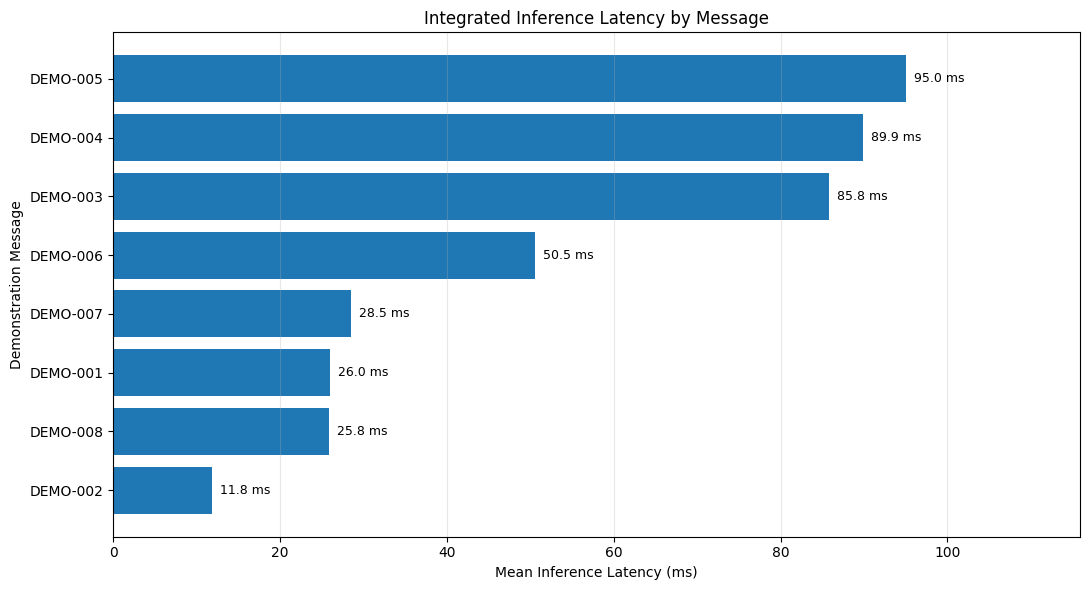

INTEGRATED INFERENCE PERFORMANCE SUMMARY
number_of_demo_messages: 8
benchmark_runs_per_message: 5
warmup_runs_per_message: 2
overall_mean_latency_ms: 51.66
legitimate_mean_latency_ms: 18.88
scam_mean_latency_ms: 62.58
total_model_parameters: 267836189
device: cuda
level_2_execution_count: 6

Saved artifacts:
integrated_inference_latency.png
integrated_inference_latency.pdf
inference_performance_summary.json

Visualization and summary export completed.


In [21]:
# ============================================================
# Cell 16: Integrated Inference Performance Visualization
# ============================================================

import matplotlib.pyplot as plt
import json

# ------------------------------------------------------------
# Prepare summary statistics
# ------------------------------------------------------------

summary = {
    "number_of_demo_messages": int(len(latency_df)),
    "benchmark_runs_per_message": BENCHMARK_RUNS,
    "warmup_runs_per_message": WARMUP_RUNS,
    "overall_mean_latency_ms": round(
        float(latency_df["mean_latency_ms"].mean()), 2
    ),
    "legitimate_mean_latency_ms": round(
        float(
            latency_df.loc[
                latency_df["predicted_label"] == "legitimate",
                "mean_latency_ms"
            ].mean()
        ), 2
    ),
    "scam_mean_latency_ms": round(
        float(
            latency_df.loc[
                latency_df["predicted_label"] == "financial_scam",
                "mean_latency_ms"
            ].mean()
        ), 2
    ),
    "total_model_parameters": int(total_parameters),
    "device": str(DEVICE),
    "level_2_execution_count": int(
        latency_df["level_2_executed"].sum()
    )
}

# ------------------------------------------------------------
# Plot message-level inference latency
# ------------------------------------------------------------

plot_df = latency_df.sort_values(
    "mean_latency_ms", ascending=True
).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    plot_df["demo_id"],
    plot_df["mean_latency_ms"]
)

ax.set_title("Integrated Inference Latency by Message")
ax.set_xlabel("Mean Inference Latency (ms)")
ax.set_ylabel("Demonstration Message")
ax.grid(axis="x", alpha=0.3)

for bar, (_, row) in zip(bars, plot_df.iterrows()):
    ax.text(
        bar.get_width() + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{row['mean_latency_ms']:.1f} ms",
        va="center",
        fontsize=9
    )

ax.set_xlim(
    0,
    plot_df["mean_latency_ms"].max() * 1.22
)

plt.tight_layout()

png_path = (
    INFERENCE_OUTPUT_DIR /
    "integrated_inference_latency.png"
)

pdf_path = (
    INFERENCE_OUTPUT_DIR /
    "integrated_inference_latency.pdf"
)

plt.savefig(png_path, dpi=300, bbox_inches="tight")
plt.savefig(pdf_path, bbox_inches="tight")
plt.show()

plt.close(fig)

# ------------------------------------------------------------
# Export performance summary
# ------------------------------------------------------------

summary_json_path = (
    INFERENCE_OUTPUT_DIR /
    "inference_performance_summary.json"
)

with open(summary_json_path, "w", encoding="utf-8") as file:
    json.dump(summary, file, indent=4)

print("=" * 85)
print("INTEGRATED INFERENCE PERFORMANCE SUMMARY")
print("=" * 85)

for key, value in summary.items():
    print(f"{key}: {value}")

print("\nSaved artifacts:")
print(png_path.name)
print(pdf_path.name)
print(summary_json_path.name)

print("\nVisualization and summary export completed.")


## Conclusion

This notebook integrates the previously trained binary DistilBERT classifier with three independently trained multi-level classification models into a conditional inference pipeline.

Given an input message, the system first performs binary financial scam classification. Messages classified as legitimate terminate at this stage, while messages classified as financial scams are passed to the second-level models for:

- **Scam subtype classification:** 13 categories
- **Fraudulent intent classification:** 5 categories
- **Social engineering tactic detection:** 9 multilabel categories

### Demonstration Results

The integrated pipeline was demonstrated using eight messages selected from four data sources:

- Real legitimate messages
- Real-world external scam messages
- V3.1 synthetic scam messages
- LLM-authored synthetic scam messages

All eight messages received the expected binary classification in this demonstration. Six were routed to second-level analysis.

Second-level predictions were compared with available annotations for the synthetic messages. The comparison demonstrated correct and incorrect predictions across different tasks, illustrating both the capabilities and limitations of the integrated framework.

Second-level predictions on real-world external scam messages were treated as exploratory outputs because corresponding real-world subtype, intent, and tactic ground truth was not established for this demonstration.

### Computational Performance

The inference pipeline was measured on an NVIDIA Tesla T4 GPU.

| Metric | Result |
|---|---:|
| Demonstration messages | 8 |
| Warm-up runs per message | 2 |
| Measured runs per message | 5 |
| Overall mean latency | 51.66 ms |
| Legitimate-path mean latency | 18.88 ms |
| Scam-path mean latency | 62.58 ms |
| Total model parameters | 267,836,189 |

The difference in latency reflects the conditional execution design: legitimate predictions require only the binary classifier, whereas scam predictions invoke all four models.

These measurements are illustrative results from a small demonstration sample, not a comprehensive latency benchmark.

### Limitations

1. The demonstration contains only eight messages and does not establish generalization performance.
2. Real-world second-level predictions are exploratory due to the absence of corresponding verified annotations.
3. Synthetic second-level comparisons are qualitative demonstrations, not replacements for the quantitative experiments reported in Notebook 11.
4. Inference latency may vary with input length, hardware, batching, and execution conditions.
5. The framework depends on the binary classifier's initial decision; a false negative prevents second-level analysis from being executed.

### Final Outcome

The notebook demonstrates the operational integration of binary scam detection, multi-level scam analysis, and conditional inference into a unified framework.

No model retraining or additional benchmark evaluation was performed. Quantitative model-performance claims remain grounded in the preceding experimental notebooks.
